# Customer Churn Prediction Using Machine Learning

This notebook explores customer churn data and compares Logistic Regression with Random Forest.

**Dataset required:** IBM Telco Customer Churn CSV. Download the dataset and save it as
`dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv` in the project root.

The notebook creates evaluation charts in `images/` and saves the best pipeline in `models/`.

## 1. Import libraries

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score
)

os.makedirs("../images", exist_ok=True)
os.makedirs("../models", exist_ok=True)

RANDOM_STATE = 42

In [2]:
import os

print(os.getcwd())

D:\beewonder🐝\Customer-Churn-Prediction\notebooks


## 2. Load the dataset

In [3]:
DATA_PATH = "../dataset/Telco-Customer-Churn.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Dataset not found at {DATA_PATH}")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand and clean the data

In [4]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).head(15))

# In the IBM Telco dataset, TotalCharges can contain blank strings.
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Drop customerID because it is an identifier, not a useful predictive feature.
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# Remove duplicate rows, if any.
df = df.drop_duplicates().copy()

print("Cleaned dataset shape:", df.shape)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecu

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
dtype: int64

Cleaned dataset shape: (7021, 20)


## 4. Exploratory Data Analysis

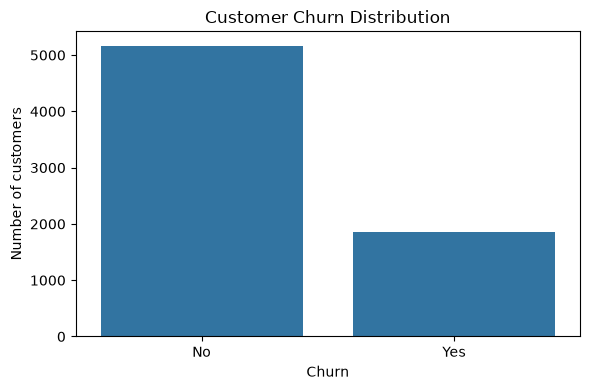

Churn rate: 26.45%


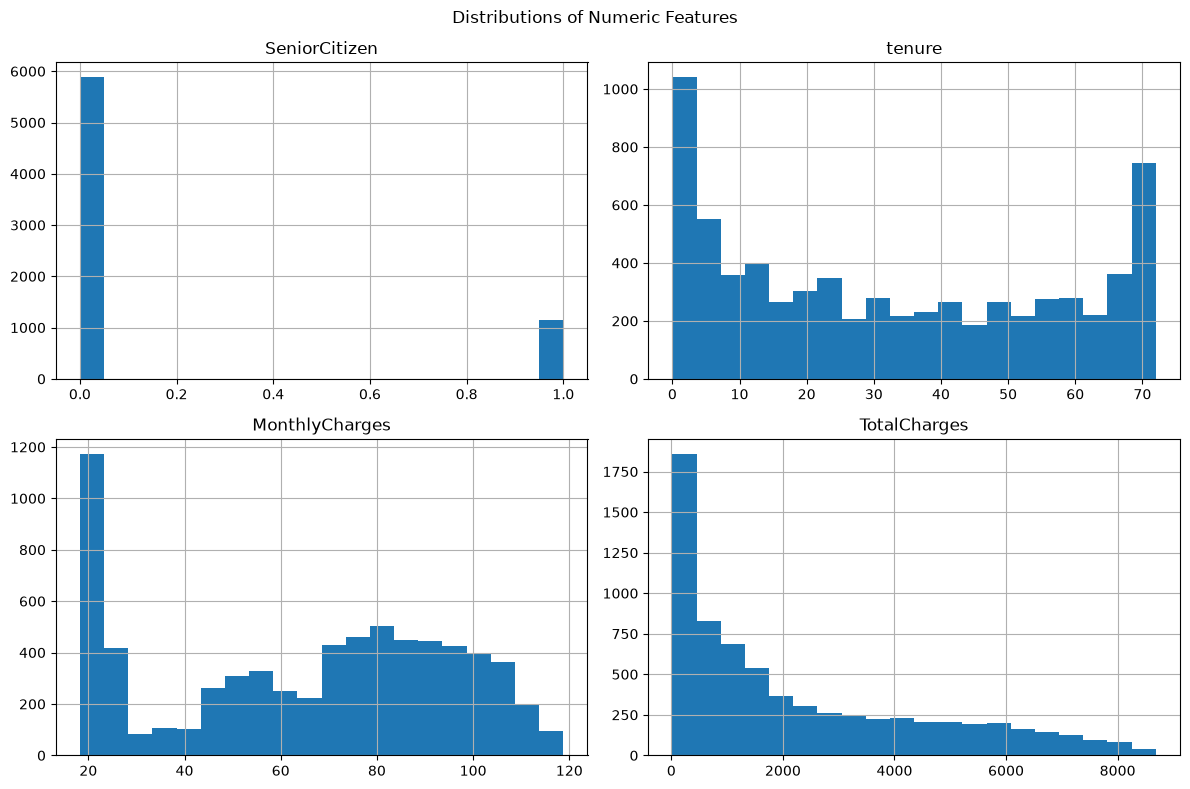

In [5]:
if "Churn" not in df.columns:
    raise ValueError("Expected target column 'Churn' was not found in the dataset.")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.savefig("../images/churn_distribution.png", dpi=150)
plt.show()

churn_rate = (df["Churn"].astype(str).str.strip().str.lower() == "yes").mean() * 100
print(f"Churn rate: {churn_rate:.2f}%")

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    df[numeric_cols].hist(figsize=(12, 8), bins=20)
    plt.suptitle("Distributions of Numeric Features")
    plt.tight_layout()
    plt.savefig("../images/numeric_feature_distributions.png", dpi=150)
    plt.show()

## 5. Prepare features and target

In [6]:
X = df.drop(columns=["Churn"])
y = df["Churn"].astype(str).str.strip().str.lower().map({"yes": 1, "no": 0})

if y.isna().any():
    raise ValueError("Target column must contain only Yes/No values.")

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 5616
Testing rows: 1405


## 6. Train and compare machine learning models

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced"
    )
}

results = []
trained_pipelines = {}

for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    }
    results.append(row)
    trained_pipelines[model_name] = pipeline

results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.740,0.506,0.777,0.613,0.840
1,Random Forest,0.764,0.549,0.602,0.574,0.816


## 7. Compare model performance

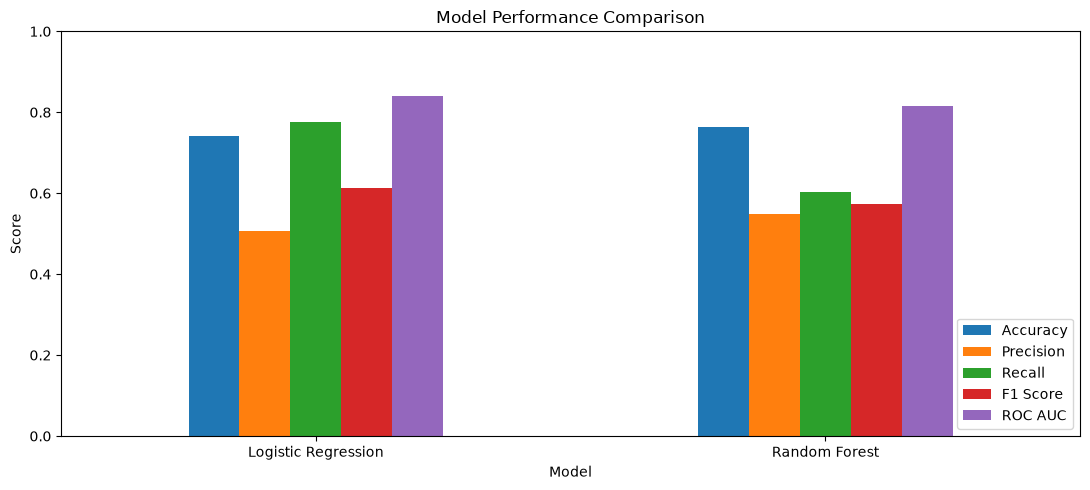

In [8]:
plot_df = results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]]
ax = plot_df.plot(kind="bar", figsize=(11, 5), ylim=(0, 1), rot=0)
ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../images/model_comparison.png", dpi=150)
plt.show()

## 8. Evaluate the best model

Best model based on F1 Score: Logistic Regression
\nClassification report:
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.80      1033
       Churn       0.51      0.78      0.61       372

    accuracy                           0.74      1405
   macro avg       0.70      0.75      0.71      1405
weighted avg       0.80      0.74      0.75      1405



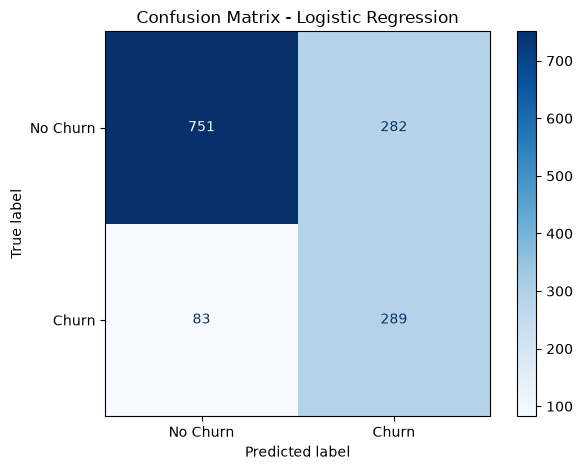

In [9]:
best_model_name = results_df.iloc[0]["Model"]
best_pipeline = trained_pipelines[best_model_name]
best_predictions = best_pipeline.predict(X_test)

print("Best model based on F1 Score:", best_model_name)
print("\\nClassification report:")
print(classification_report(y_test, best_predictions, target_names=["No Churn", "Churn"]))

cm = confusion_matrix(y_test, best_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"])
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.savefig("../images/confusion_matrix.png", dpi=150)
plt.show()

## 9. Save the trained model

In [10]:
model_path = "../models/customer_churn_pipeline.joblib"
joblib.dump(best_pipeline, model_path)
print(f"Saved model to: {model_path}")

Saved model to: ../models/customer_churn_pipeline.joblib


## 10. Try a prediction for one test customer

In [11]:
sample_customer = X_test.iloc[[0]]
actual_value = int(y_test.iloc[0])
predicted_value = int(best_pipeline.predict(sample_customer)[0])
predicted_probability = float(best_pipeline.predict_proba(sample_customer)[0, 1])

print("Actual churn:", "Yes" if actual_value == 1 else "No")
print("Predicted churn:", "Yes" if predicted_value == 1 else "No")
print(f"Predicted churn probability: {predicted_probability:.2%}")
display(sample_customer)

Actual churn: No
Predicted churn: Yes
Predicted churn probability: 88.80%


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
5627,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,74.85,485.25


## 11. Conclusion

This project:
- Examined customer churn patterns.
- Cleaned and prepared customer data.
- Trained Logistic Regression and Random Forest models.
- Compared the models using accuracy, precision, recall, F1 score and ROC AUC.
- Saved the best-performing pipeline for future predictions.

Use the actual metric values shown in your notebook when describing project results on your resume. Do not claim a model score before running the notebook.